# 02 · Explore images and patients in the retained development data

Recreate the original EDA's schema, class balance, patient contribution and feature-share/rate figures on the clean population. These describe sampling, not causes of melanoma.

Read the stages in numerical order. Training uses separate, explicitly invoked runners; executing this notebook only loads development data and saved artifacts.

Original notebooks, images, checkpoints and results remain available. The reserved test is outside this workflow.

**Original methods and figure reference:** [02_data_exploration.ipynb](../Subset/02_data_exploration.ipynb). Read [method coverage](METHOD_COVERAGE.md) for retained methods and declared adaptations.

## Load the frozen clean development dataset

In [1]:
NOTEBOOK_STAGE = '02_clean_data_eda'
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from melanoma_detection.development_dataset import load_development_dataset, load_preserved_inner_memberships
from melanoma_detection.dedup_workflow import load_context, latest_evaluation, load_clean_scores, load_image_report, load_uncertainty_report, read_json, project_path, DIRECTORY, METADATA_SUITE, UNCERTAINTY
get_ipython().run_line_magic("matplotlib", "inline")
MANIFEST = "data/subset/processed/dedup_v1/dataset_manifest.json"
data, dataset_identity = load_development_dataset(ROOT, dataset_manifest=MANIFEST)
context = load_context(ROOT)
plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
FIGURE_DIR = ROOT / DIRECTORY / "figures" / NOTEBOOK_STAGE
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def finish_figure(figure, filename):
    if not filename or Path(filename).name != filename:
        raise ValueError("Figure name must be a simple stem.")
    figure.savefig(FIGURE_DIR / (filename + ".png"), dpi=180, bbox_inches="tight")
    figure.savefig(FIGURE_DIR / (filename + ".pdf"), bbox_inches="tight")
    plt.show()
    plt.close(figure)

_score_bundle = None
def score_bundle():
    global _score_bundle
    if _score_bundle is None:
        _score_bundle = load_clean_scores(ROOT)
    return _score_bundle
display(pd.DataFrame([{"Images": len(data), "Malignant images": int(data.target.sum()),
    "Patients": data.patient_id.nunique(), "Malignant patients": data.loc[data.target.eq(1), "patient_id"].nunique()}]))
display(Markdown("**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training."))

def show_saved_table(relative, limit=30):
    path = project_path(ROOT, relative)
    if not path.exists():
        display(Markdown("**Pending:** " + relative + ". No results are inferred from unfinished runs."))
        return pd.DataFrame()
    table = pd.read_csv(path)
    display(table.head(limit))
    if len(table) > limit:
        display(Markdown(f"Showing {limit} of {len(table)} rows; the complete CSV is saved."))
    return table

def comparison_table():
    evaluation = latest_evaluation(ROOT)
    if "output_directory" not in evaluation:
        display(Markdown("**Pending:** clean evaluation has not been generated."))
        return pd.DataFrame()
    path = project_path(ROOT, evaluation["output_directory"] + "/model_comparison.csv")
    return pd.read_csv(path)

def model_chart(table, title):
    if table.empty:
        display(Markdown("**Pending:** no verified scores are available for this stage."))
        return
    table = table.sort_values("average_precision")
    fig, ax = plt.subplots(figsize=(9, max(3.2, .38 * len(table) + 1.5)), layout="constrained")
    ax.barh(table.model, table.average_precision, color="#276b91")
    ax.set(title=title, xlabel="Unweighted mean outer-fold average precision", xlim=(0, max(.1, float(table.average_precision.max()) * 1.25)))
    finish_figure(fig, "model_comparison_ap")

def pilot_report(run_id):
    directory = ROOT / "results/image_d1_runs" / run_id
    path = directory / "summary.json"
    summary = read_json(path) if path.exists() else {"status": "pending"}
    if summary.get("status") == "complete":
        manifest = read_json(directory / "run_manifest.json")
        if manifest["dataset_identity"] != dataset_identity:
            raise ValueError("Pilot belongs to another dataset.")
        from melanoma_detection.development_dataset import sha256_file
        for relative, digest in summary["artifact_sha256"].items():
            artifact = (directory / relative).resolve()
            if not artifact.is_relative_to(directory.resolve()) or sha256_file(artifact) != digest:
                raise ValueError("Completed pilot artifact changed.")
    return directory, summary


,Images,Malignant images,Patients,Malignant patients
0,6706,127,422,88


**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training.

## 1. Inspect schema, records and required image coverage

The image IDs in the frozen manifest define the population; an image directory is not a dataset definition. Check each retained JPEG exists without treating excluded copies or unrelated files as errors. A five-row preview illustrates formatting, not the full distribution.

In [2]:
display(pd.DataFrame({"dtype": data.dtypes.astype(str), "filled": data.notna().sum(), "distinct_values": data.nunique(dropna=False)}))
display(data.head())
missing = [name for name in sorted(data.image_name) if not (ROOT / "data/subset/train" / (name + ".jpg")).is_file()]
assert not missing and data.image_name.is_unique
assert data.groupby("patient_id").fold.nunique().eq(1).all()
display(pd.DataFrame([{"retained_JPEGs_required": len(data), "missing_required_JPEGs": len(missing),
    "excluded_copies_preserved_on_disk": int(context["ledger"].decision.eq("excluded").sum())}]))

,dtype,filled,distinct_values
image_name,str,6706,6706
patient_id,str,6706,422
sex,str,6706,2
age_approx,int64,6706,16
anatom_site_general_challenge,str,6706,7
diagnosis,str,6706,8
benign_malignant,str,6706,2
target,int8,6706,2
fold,int64,6706,5


,image_name,patient_id,sex,age_approx,anatom_site_general_challenge,diagnosis,benign_malignant,target,fold
0,ISIC_0015719,IP_3075186,female,45,upper extremity,unknown,benign,0,0
1,ISIC_0074542,IP_4698288,male,25,lower extremity,unknown,benign,0,1
2,ISIC_0076545,IP_9802602,male,55,upper extremity,unknown,benign,0,2
3,ISIC_0082348,IP_7684360,male,55,torso,unknown,benign,0,0
4,ISIC_0085172,IP_1705144,female,50,lower extremity,unknown,benign,0,1


,retained_JPEGs_required,missing_required_JPEGs,excluded_copies_preserved_on_disk
0,6706,0,158


## 2. Compare the image and patient analysis units

Image prevalence is malignant images divided by images. Patient prevalence is patients with at least one malignant image divided by patients. A person can have both benign and malignant photographs. The two rates answer different questions and should not be used interchangeably.

,analysis_unit,units,positive_units,malignant_rate
0,Images,6706,127,0.018938
1,Patients,422,88,0.208531


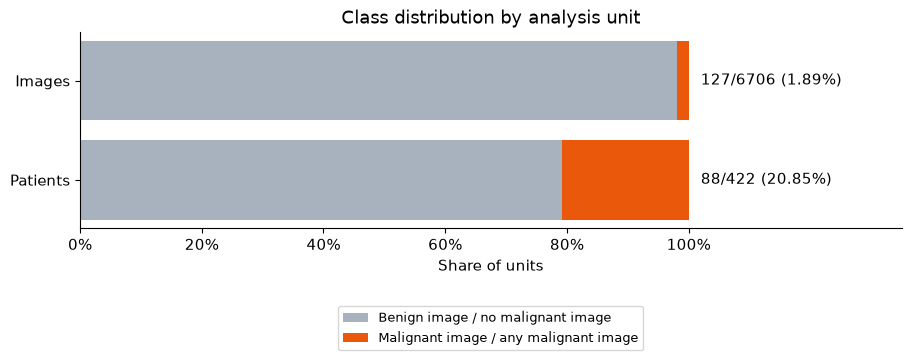

In [3]:
patients = data.groupby("patient_id", as_index=False).agg(images=("image_name", "size"),
    malignant_images=("target", "sum"), any_malignant=("target", "max"), fold=("fold", "first"))
units = pd.DataFrame([{ "analysis_unit":"Images", "units":len(data), "positive_units":int(data.target.sum())},
    {"analysis_unit":"Patients", "units":len(patients), "positive_units":int(patients.any_malignant.sum())}])
units["malignant_rate"] = units.positive_units / units.units
display(units)
from matplotlib.ticker import PercentFormatter
fig, ax = plt.subplots(figsize=(9, 3.4), layout="constrained")
ax.barh(units.analysis_unit, 1-units.malignant_rate, color="#a8b1be", label="Benign image / no malignant image")
ax.barh(units.analysis_unit, units.malignant_rate, left=1-units.malignant_rate, color="#ea580c", label="Malignant image / any malignant image")
for i,row in units.iterrows(): ax.text(1.02, i, f"{row.positive_units}/{row.units} ({row.malignant_rate:.2%})", va="center")
ax.set(xlim=(0,1.35), xticks=np.linspace(0,1,6), title="Class distribution by analysis unit", xlabel="Share of units")
ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.legend(loc="lower center", bbox_to_anchor=(.5,-.65), fontsize=9)
finish_figure(fig, "class_balance_images_patients")

## 3. Show unequal patient contributions

The histogram reproduces the original image-count view. The median and tail show why images are not independent: patients with many images receive more weight. Deduplication reduces exact-copy weight, while paired patient bootstrap and equal-patient diagnostics address the remaining clustering.

,images_per_patient
0.00,3.00
0.25,5.00
0.50,12.00
0.75,21.00
0.90,34.00
0.95,40.00
0.99,88.01
1.00,115.00


,top_ten_patient_image_share
0,0.124217


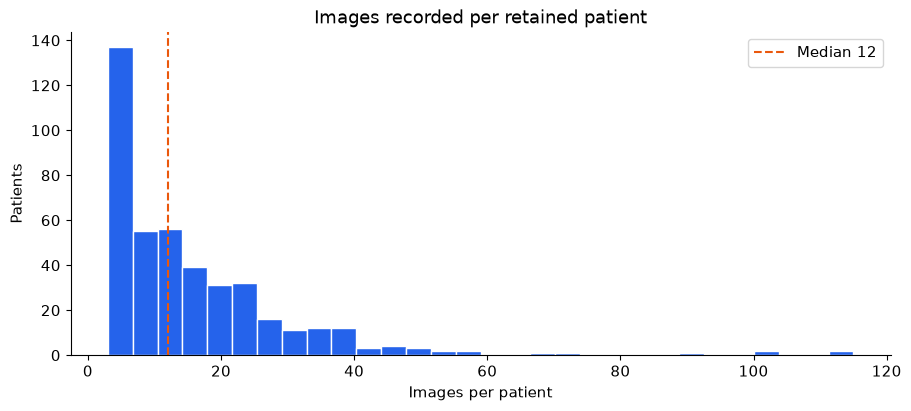

In [4]:
display(patients.images.quantile([0,.25,.5,.75,.9,.95,.99,1]).rename("images_per_patient").to_frame())
display(pd.DataFrame([{"top_ten_patient_image_share": patients.images.nlargest(10).sum()/len(data)}]))
fig, ax = plt.subplots(layout="constrained")
ax.hist(patients.images, bins=30, color="#2563eb", edgecolor="white")
ax.axvline(patients.images.median(), color="#ea580c", ls="--", label=f"Median {patients.images.median():.0f}")
ax.set(title="Images recorded per retained patient", xlabel="Images per patient", ylabel="Patients"); ax.legend()
finish_figure(fig, "images_per_patient")

## 4. Define matching feature summaries

For sex, five-year age bucket and anatomical site, reproduce the original two-panel comparison: category share and malignancy rate. Count each patient once within a category, using the maximum label among their images in that category. A patient with several ages or sites may appear in more than one category. As in the original, the gold category-share denominator is the sum of patient-category memberships, which can exceed 422; it is not the number of unique people. Each feature's shares therefore sum to 100%.

In [5]:
def category_summary(frame, column):
    image = frame.groupby(column, dropna=False).target.agg(image_count="size", malignant_images="sum", image_rate="mean")
    per_patient = frame.groupby([column,"patient_id"], dropna=False).target.max().reset_index()
    patient = per_patient.groupby(column, dropna=False).target.agg(patient_count="size", malignant_patients="sum", patient_rate="mean")
    table = image.join(patient)
    table["image_share"] = table.image_count / len(frame)
    table["patient_share"] = table.patient_count / table.patient_count.sum()
    if column == "age_approx": table = table.sort_index(key=lambda idx: pd.to_numeric(idx, errors="coerce"))
    else: table = table.sort_values("image_count",ascending=False)
    table["rate_difference_pp"] = 100 * (table.patient_rate - table.image_rate)
    return table
def category_plot(table, title, filename):
    fig, axes = plt.subplots(1,2, figsize=(13,max(4,.4*len(table)+1.3)), layout="constrained")
    pos = np.arange(len(table))
    for ax, a, b, label in [(axes[0],"image_share","patient_share","Category share"), (axes[1],"image_rate","patient_rate","Malignancy rate")]:
        ax.barh(pos-.18,table[a],height=.34,color="#2563eb",label="Images")
        ax.barh(pos+.18,table[b],height=.34,color="#d4a72c",label="Patient-category memberships")
        ax.set(yticks=pos,yticklabels=table.index.astype(str),title=title+": "+label,xlabel=label)
        ax.invert_yaxis(); ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.legend(fontsize=8)
        ax.grid(axis="x",alpha=.2); ax.set_axisbelow(True)
    finish_figure(fig,filename)
display(Markdown("These are unadjusted descriptive rates. Read malignant-patient support beside a rate, especially in small categories."))
display(pd.DataFrame([{"field":column,"patients":data.patient_id.nunique(),
    "patients_in_multiple_categories":int(data.groupby("patient_id")[column].nunique().gt(1).sum())}
    for column in ["sex","age_approx","anatom_site_general_challenge"]]))

These are unadjusted descriptive rates. Read malignant-patient support beside a rate, especially in small categories.

,field,patients,patients_in_multiple_categories
0,sex,422,0
1,age_approx,422,204
2,anatom_site_general_challenge,422,388


## 5. Compare recorded sex

Read the blue and gold bars on the same scale. Differences can reflect the number of images per patient rather than different numbers of people. The rate panel is descriptive and does not isolate sex from age, site or collection effects.

,image_count,malignant_images,image_rate,patient_count,malignant_patients,patient_rate,image_share,patient_share,rate_difference_pp
sex,,,,,,,,,
female,3477,53,0.015243,204,37,0.181373,0.518491,0.483412,16.612952
male,3229,74,0.022917,218,51,0.233945,0.481509,0.516588,21.102764


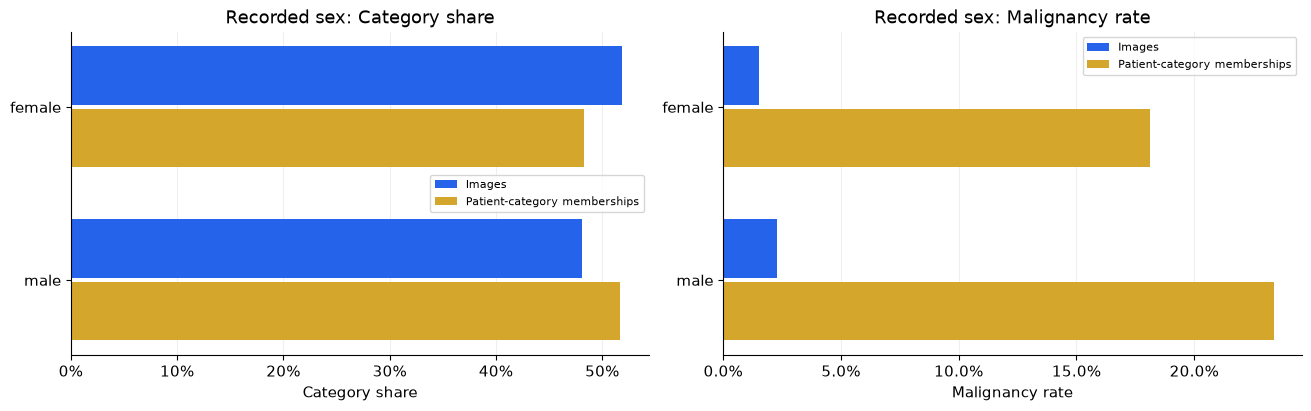

In [6]:
sex_table = category_summary(data,"sex")
display(sex_table)
category_plot(sex_table,"Recorded sex","sex_image_patient_share_rates")

## 6. Compare the recorded age buckets

Keep the original five-year bucket representation for EDA. The models later compare categorical age with a cubic spline or standardized numeric age. A patient is counted within every recorded bucket they occupy; we do not replace their ages with one guessed value.

,image_count,malignant_images,image_rate,patient_count,malignant_patients,patient_rate,image_share,patient_share,rate_difference_pp
age_approx,,,,,,,,,
15,18,1,0.055556,5,1,0.200000,0.002684,0.006906,14.444444
20,169,2,0.011834,12,2,0.166667,0.025201,0.016575,15.483235
25,413,4,0.009685,32,4,0.125000,0.061587,0.044199,11.531477
30,483,6,0.012422,53,3,0.056604,0.072025,0.073204,4.418141
35,465,3,0.006452,61,3,0.049180,0.069341,0.084254,4.272871
40,616,6,0.009740,70,3,0.042857,0.091858,0.096685,3.311688
45,817,10,0.012240,86,9,0.104651,0.121831,0.118785,9.241126
50,804,10,0.012438,87,10,0.114943,0.119893,0.120166,10.250472
55,987,18,0.018237,92,9,0.097826,0.147182,0.127072,7.958900


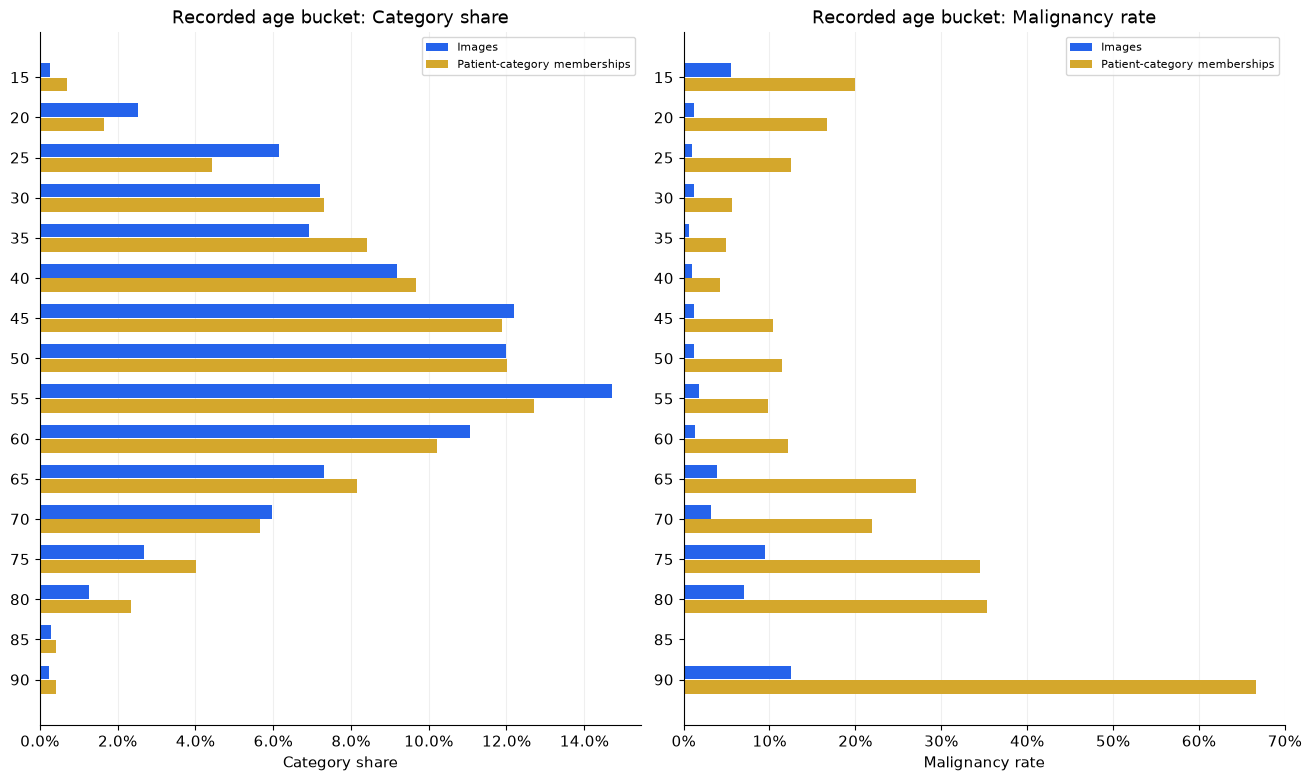

,patients_multiple_ages,patients_age_span_at_least_15
0,204,41


In [7]:
age_table = category_summary(data,"age_approx")
display(age_table)
category_plot(age_table,"Recorded age bucket","age_image_patient_share_rates")
profiles = pd.read_csv(ROOT / "results/dedup_v1/audit/patient_profile_retained.csv")
display(pd.DataFrame([{"patients_multiple_ages": int(profiles.distinct_ages.gt(1).sum()),
    "patients_age_span_at_least_15":int(profiles.age_span.ge(15).sum())}]))

## 7. Compare anatomical site and missing-site support

Unknown remains a category. A high or low rate in that group rests on very few malignant patients and cannot support a general subgroup conclusion. Patients with both known and unknown sites can contribute to both counts.

,image_count,malignant_images,image_rate,patient_count,malignant_patients,patient_rate,image_share,patient_share,rate_difference_pp
anatom_site_general_challenge,,,,,,,,,
torso,3351,54,0.016115,398,41,0.103015,0.499702,0.302662,8.690048
lower extremity,1620,25,0.015432,327,23,0.070336,0.241575,0.248669,5.490429
upper extremity,1044,22,0.021073,298,17,0.057047,0.155681,0.226616,3.597418
head/neck,393,21,0.053435,179,21,0.117318,0.058604,0.136122,6.388332
Unknown,195,2,0.010256,53,2,0.037736,0.029078,0.040304,2.747944
palms/soles,70,0,0.000000,40,0,0.000000,0.010438,0.030418,0.000000
oral/genital,33,3,0.090909,20,2,0.100000,0.004921,0.015209,0.909091


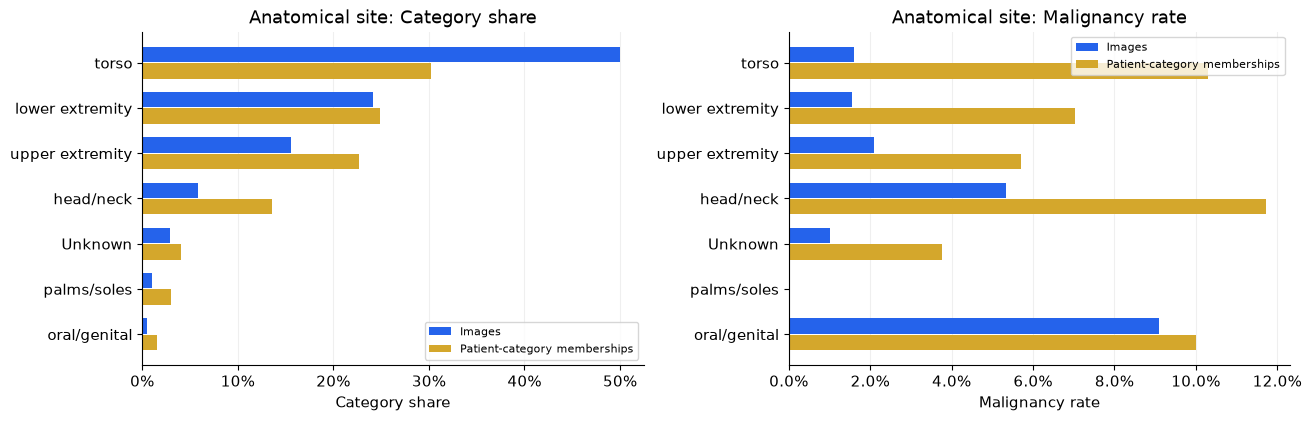

,fold,target,site_missing,images,patients
0,0,0,False,1287,84
1,0,0,True,33,15
2,0,1,False,23,16
3,0,1,True,1,1
4,1,0,False,1331,84
5,1,0,True,9,7
6,1,1,False,26,15
7,2,0,False,1278,87
8,2,0,True,24,13
9,2,1,False,25,21


,fold,target,site_missing,images,patients
0,0,0,False,1287,84
1,0,0,True,33,15
2,0,1,False,23,16
3,0,1,True,1,1
4,1,0,False,1331,84
5,1,0,True,9,7
6,1,1,False,26,15
7,2,0,False,1278,87
8,2,0,True,24,13
9,2,1,False,25,21


In [8]:
site_table = category_summary(data,"anatom_site_general_challenge")
display(site_table)
category_plot(site_table,"Anatomical site","site_image_patient_share_rates")
show_saved_table("results/dedup_v1/audit/missing_site_by_fold_label_retained.csv")

## 8. Check diagnoses and draw the EDA implications

Diagnosis and benign/malignant text should agree with the target, but would reveal the answer if supplied to a model. The observed collection is imbalanced, clustered by patient and unevenly represented across metadata categories. This motivates rare-positive ranking metrics and grouped evaluation, not diagnosis-derived features.

In [9]:
display(data.groupby("diagnosis").target.agg(images="size",malignant_images="sum",malignancy_rate="mean"))
display(pd.DataFrame([{"image_prevalence":data.target.mean(),"any_malignant_patient_prevalence":patients.any_malignant.mean(),
    "patients":len(patients),"median_images_per_patient":patients.images.median(),"maximum_images_per_patient":patients.images.max()}]))
display(Markdown("**Next:** verify the existing outer and inner memberships. These plots are development sampling descriptions; they are not risk estimates for a clinical population."))

,images,malignant_images,malignancy_rate
diagnosis,,,
cafe-au-lait macule,1,0,0.0
lentigo NOS,8,0,0.0
lichenoid keratosis,14,0,0.0
melanoma,127,127,1.0
nevus,1107,0,0.0
seborrheic keratosis,27,0,0.0
solar lentigo,1,0,0.0
unknown,5421,0,0.0


,image_prevalence,any_malignant_patient_prevalence,patients,median_images_per_patient,maximum_images_per_patient
0,0.018938,0.208531,422,12.0,115


**Next:** verify the existing outer and inner memberships. These plots are development sampling descriptions; they are not risk estimates for a clinical population.

## Interpretation boundary

These are development results. Patient grouping protects separation between fitting and validation; bootstrap intervals condition on saved models. Sparse subgroups and selected inner-validation pilots cannot establish a final winner. No reserved-test conclusion is made.